# Phân tích thực nghiệm 24 người (Tuần 9)

Theo proposal §4 (RQ1, H0/H1), §5.5, §5.10 và §6, cùng các quyết định chốt trước phân tích ghi trong `notes.md` (2026-11-11 16:55).
Đầu vào: `results/thucnghiem_24/phien/<session_id>/grade/summary.json` (kết quả `junit_eval.py`), `tool_r1/summary.json` (báo cáo công cụ đầu tiên), `data/lich_phien_thucnghiem_24.csv`, `data/frozen/main12/frozen_index.json`.
Đầu ra: `results/summary.csv`, `results/excluded.csv`, `results/figures/fig1_distribution.png`, `results/figures/fig2_comparison.png`.

Thứ tự: (1) kiểm dữ liệu, (2) N dự kiến / N hợp lệ, (3) thống kê mô tả và hình phân phối, (4) kiểm giả định, (5) kiểm định chính, (6) effect size, (7) phân tích bổ sung và độ nhạy đã nêu trong §6, (8) kết luận RQ1.
Mọi phân tích không có trong proposal được gắn nhãn **exploratory**.

In [1]:
import sys, json, csv, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT / 'tools' / 'gap1-pilot'))
import compute_metric as cm
PHIEN = ROOT / 'results' / 'thucnghiem_24' / 'phien'
LICH = ROOT / 'data' / 'lich_phien_thucnghiem_24.csv'
FROZEN = json.load(open(ROOT / 'data' / 'frozen' / 'main12' / 'frozen_index.json', encoding='utf-8'))['problems']
FIG = ROOT / 'results' / 'figures'; FIG.mkdir(exist_ok=True)
T, ALPHA, DELTA = 'after_T20', 0.05, 0.10
COL = {'J': '#2a78d6', 'P': '#eb6834'}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#52514e',
                     'axes.labelcolor': '#0b0b0b', 'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True,
                     'grid.color': '#e6e5e1', 'grid.linewidth': 0.6, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'savefig.dpi': 300, 'axes.axisbelow': True})
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)
lich = pd.read_csv(LICH)
print('Số phiên trong lịch:', len(lich), '| số người:', lich.sv_id.nunique())

Số phiên trong lịch: 48 | số người: 24


## 1. Kiểm dữ liệu trước khi kiểm định (9.3)

In [2]:
rows, loi = [], []
for r in lich.itertuples():
    f = PHIEN / r.session_id / 'grade' / 'summary.json'
    if not f.exists():
        loi.append((r.session_id, 'thiếu kết quả chấm')); continue
    s = json.loads(f.read_text(encoding='utf-8'))
    if s['problem_id'] != r.pid or s['put'] != r.put: loi.append((r.session_id, 'bài/PUT không khớp lịch'))
    if s['WA_mau_so'] != FROZEN[r.pid]['WA_danh_gia']: loi.append((r.session_id, 'mẫu số WA khác frozen_index'))
    if s['manifest_sha256'] != FROZEN[r.pid]['manifest_sha256']: loi.append((r.session_id, 'manifest khác SHA-256 đã khoá'))
    for k in ['before', 'after_T15', 'after_T20', 'after_T30']:
        v = s['bo_test'].get(k)
        if v is None: loi.append((r.session_id, f'thiếu bộ {k}')); continue
        for m in ['WADR', 'WADR_giu_bat_dong', 'WADR_phu']:
            if v.get(m) is not None and not (0 <= v[m] <= 1): loi.append((r.session_id, f'{k}.{m} ngoài [0, 1]'))
    t1 = PHIEN / r.session_id / 'tool_r1' / 'summary.json'
    rep = json.loads(t1.read_text(encoding='utf-8')) if t1.exists() else None
    rows.append({'session_id': r.session_id, 'sv_id': r.sv_id, 'pid': r.pid, 'dk': 'P' if r.tool == 'pitest' else 'J',
                 'phien': r.thu_tu_phien, 'slot': r.slot, 'WA': s['WA_mau_so'], 'summary': s, 'rep': rep})
# ghép cặp: mỗi người đúng 2 phiên, 1 J + 1 P, khác bài, thứ tự 1 và 2
for sv, g in lich.groupby('sv_id'):
    if len(g) != 2 or set(g.tool) != {'jacoco', 'pitest'} or g.pid.nunique() != 2 or set(g.thu_tu_phien) != {1, 2}:
        loi.append((sv, 'ghép cặp sai'))
# lịch crossover: mỗi tổ hợp (bài, phiên, công cụ) xuất hiện đúng 1 lần
dup = lich.groupby(['pid', 'thu_tu_phien', 'tool']).size()
if (dup != 1).any(): loi.append(('lịch', 'tổ hợp (bài, phiên, công cụ) không đúng 1 lần'))
print('Số dòng lỗi:', len(loi)); print(loi if loi else 'Không có lỗi: đủ 48 phiên, khớp lịch, khớp manifest đã khoá, metric trong [0, 1], ghép cặp đúng.')

Số dòng lỗi: 0
Không có lỗi: đủ 48 phiên, khớp lịch, khớp manifest đã khoá, metric trong [0, 1], ghép cặp đúng.


Bảng phiên (WADR theo `compute_metric.py`; bộ không biên dịch: Before = 0, After = không tính ở phân tích chính).

In [3]:
def w(s, k, m='WADR'):
    # WADR tính lại từ số đếm như compute_metric.py; WADR_giu_bat_dong chỉ có dạng đã làm tròn 4 chữ số trong summary.json
    v = s['bo_test'][k]
    if v.get('bien_dich') != 'ok':
        return 0.0 if k == 'before' else None
    cnt = {'WADR': 'WA_phat_hien_assertion', 'WADR_phu': 'WA_phat_hien_assertion_hoac_ngoai_le'}.get(m)
    return v[cnt] / s['WA_mau_so'] if cnt else v.get(m)
def empty_report(rep, dk):
    if rep is None: return None   # không có báo cáo (Before không biên dịch)
    return (rep.get('dong_con_nhanh_chua_phu', 1) == 0) if dk == 'J' else (rep.get('mutant_song_sot_hoac_khong_phu', 1) == 0)
ph = pd.DataFrame([{**{k: r[k] for k in ['session_id', 'sv_id', 'pid', 'dk', 'phien', 'slot', 'WA']},
                    'bien_dich_before': r['summary']['bo_test']['before']['bien_dich'],
                    'bien_dich_after': r['summary']['bo_test'][T]['bien_dich'],
                    'WADR_before': w(r['summary'], 'before'), 'WADR_after': w(r['summary'], T),
                    'WADR_after_T15': w(r['summary'], 'after_T15'), 'WADR_after_T30': w(r['summary'], 'after_T30'),
                    'phu_before': w(r['summary'], 'before', 'WADR_phu'), 'phu_after': w(r['summary'], T, 'WADR_phu'),
                    'giu_before': w(r['summary'], 'before', 'WADR_giu_bat_dong'), 'giu_after': w(r['summary'], T, 'WADR_giu_bat_dong'),
                    'dau_vao_after': r['summary']['bo_test'][T].get('dau_vao_doc_lap'),
                    'bat_dong_AC_after': len(r['summary']['bo_test'][T].get('test_bat_dong_AC') or []),
                    'co_bao_cao': r['rep'] is not None, 'bao_cao_rong': empty_report(r['rep'], r['dk'])} for r in rows])
ph['dWADR'] = ph.WADR_after - ph.WADR_before
# đối chiếu với compute_metric.py (script chính đã kiểm bằng ca tính tay)
cmr = {s['session_id']: s for s in cm.load_sessions(PHIEN, LICH, T, 'bo')}
assert all((pd.isna(r.dWADR) and cmr[r.session_id]['dWADR'] is None) or abs(r.dWADR - cmr[r.session_id]['dWADR']) < 1e-12 for r in ph.itertuples())
print('ΔWADR khớp compute_metric.py ở cả 48 phiên.')
ph[['session_id', 'pid', 'dk', 'phien', 'bien_dich_before', 'bien_dich_after', 'WADR_before', 'WADR_after', 'dWADR']].round(4)

ΔWADR khớp compute_metric.py ở cả 48 phiên.


,session_id,pid,dk,phien,bien_dich_before,bien_dich_after,WADR_before,WADR_after,dWADR
0,SV05-1,p02263,J,1,ok,ok,0.3696,0.3804,0.0109
1,SV05-2,p03633,P,2,lỗi,ok,0.0000,0.0000,0.0000
2,SV19-1,p03274,J,1,ok,ok,0.2025,0.2025,0.0000
3,SV19-2,p03351,P,2,ok,ok,0.4163,0.5928,0.1765
4,SV24-1,p03253,P,1,ok,lỗi,0.1897,NaN,NaN
5,SV24-2,p03378,J,2,ok,ok,0.2917,0.3542,0.0625
6,SV22-1,p00003,P,1,ok,ok,0.0000,0.0000,0.0000
7,SV22-2,p03416,J,2,ok,ok,0.2593,0.2593,0.0000
8,SV12-1,p03378,J,1,ok,ok,0.2917,0.4583,0.1667
9,SV12-2,p03253,P,2,ok,ok,0.1897,0.4310,0.2414


## 2. N dự kiến, N hợp lệ và các mục bị loại (`results/excluded.csv`)

In [4]:
ex = []
for r in ph[ph.WADR_after.isna()].itertuples():
    ex.append({'session_id': r.session_id, 'sv_id': r.sv_id, 'dieu_kien': r.dk, 'pid': r.pid, 'fail_type': 'method',
               'ly_do': 'After (T = 20) không biên dịch', 'pham_vi': 'loại khỏi phân tích chính; độ nhạy coi WADR(After) = 0'})
    o = ph[(ph.sv_id == r.sv_id) & (ph.session_id != r.session_id)].iloc[0]
    ex.append({'session_id': o.session_id, 'sv_id': o.sv_id, 'dieu_kien': o.dk, 'pid': o.pid, 'fail_type': '',
               'ly_do': f'phiên cùng người ({r.session_id}) bị loại nên không ghép cặp được', 'pham_vi': 'loại khỏi phân tích ghép cặp chính'})
for r in ph[ph.bien_dich_before != 'ok'].itertuples():
    ex.append({'session_id': r.session_id, 'sv_id': r.sv_id, 'dieu_kien': r.dk, 'pid': r.pid, 'fail_type': 'method',
               'ly_do': 'Before không biên dịch: WADR(Before) = 0, không có báo cáo (§5.3 quy tắc 4)',
               'pham_vi': 'giữ trong phân tích chính' if pd.notna(r.WADR_after) else 'bị loại vì After cũng không biên dịch (dòng trên)'})
excluded = pd.DataFrame(ex, columns=['session_id', 'sv_id', 'dieu_kien', 'pid', 'fail_type', 'ly_do', 'pham_vi'])
excluded.to_csv(ROOT / 'results' / 'excluded.csv', index=False, encoding='utf-8')
N_du_kien, N_toi_thieu = 48, 24
N_tham_gia = ph.sv_id.nunique()
N_hop_le = int(ph.groupby('sv_id').WADR_after.apply(lambda s: s.notna().all()).sum())
print(f'N mục tiêu (proposal) = {N_du_kien}; N tối thiểu = {N_toi_thieu}; N tham gia = {N_tham_gia} -> nghiên cứu là thăm dò (§6).')
print(f'N hợp lệ ghép cặp = {N_hop_le}/{N_tham_gia} = {N_hop_le / N_tham_gia:.1%} (ngưỡng 80%: {"đạt" if N_hop_le / N_tham_gia >= 0.8 else "không đạt"})')
print('Phiên không hợp lệ theo điều kiện (After không biên dịch):', ph[ph.WADR_after.isna()].groupby('dk').size().to_dict())
print('Phiên Before không biên dịch theo điều kiện:', ph[ph.bien_dich_before != 'ok'].groupby('dk').size().to_dict())
excluded

N mục tiêu (proposal) = 48; N tối thiểu = 24; N tham gia = 24 -> nghiên cứu là thăm dò (§6).
N hợp lệ ghép cặp = 22/24 = 91.7% (ngưỡng 80%: đạt)
Phiên không hợp lệ theo điều kiện (After không biên dịch): {'P': 2}
Phiên Before không biên dịch theo điều kiện: {'P': 2}


,session_id,sv_id,dieu_kien,pid,fail_type,ly_do,pham_vi
0,SV24-1,SV24,P,p03253,method,After (T = 20) không biên dịch,loại khỏi phân tích chính; độ nhạy coi WADR(Af...
1,SV24-2,SV24,J,p03378,,phiên cùng người (SV24-1) bị loại nên không gh...,loại khỏi phân tích ghép cặp chính
2,SV14-1,SV14,P,p03196,method,After (T = 20) không biên dịch,loại khỏi phân tích chính; độ nhạy coi WADR(Af...
3,SV14-2,SV14,J,p01125,,phiên cùng người (SV14-1) bị loại nên không gh...,loại khỏi phân tích ghép cặp chính
4,SV05-2,SV05,P,p03633,method,"Before không biên dịch: WADR(Before) = 0, khôn...",giữ trong phân tích chính
5,SV14-1,SV14,P,p03196,method,"Before không biên dịch: WADR(Before) = 0, khôn...",bị loại vì After cũng không biên dịch (dòng trên)


## 3. Thống kê mô tả và phân phối (trước khi kiểm định)

In [5]:
def mo_ta(x):
    x = pd.Series(x).dropna()
    return pd.Series({'N': len(x), 'trung_vi': x.median(), 'Q1': x.quantile(.25), 'Q3': x.quantile(.75), 'IQR': x.quantile(.75) - x.quantile(.25),
                      'nho_nhat': x.min(), 'lon_nhat': x.max(), 'trung_binh': x.mean(), 'do_lech_chuan': x.std()})
desc = pd.concat({(m, dk): mo_ta(ph.loc[ph.dk == dk, m]) for m in ['WADR_before', 'WADR_after', 'dWADR'] for dk in 'JP'}, axis=1).T
pr = pd.DataFrame(cm.paired(cm.load_sessions(PHIEN, LICH, T, 'bo')))
d = pr.loc[pr.trong_phan_tich, 'd'].astype(float).to_numpy()
desc.loc[('d = ΔWADR(P) − ΔWADR(J)', 'cặp'), :] = mo_ta(d)
print('Số người có d = 0:', int((d == 0).sum()), '| d > 0:', int((d > 0).sum()), '| d < 0:', int((d < 0).sum()))
desc.round(4)

Số người có d = 0: 4 | d > 0: 7 | d < 0: 11


N  trung_vi      Q1      Q3     IQR  nho_nhat  lon_nhat  trung_binh  do_lech_chuan
WADR_before             J    24.0    0.2593  0.0978  0.3706  0.2728    0.0000    0.6848      0.2557         0.1996
                        P    24.0    0.2065  0.0000  0.4027  0.4027    0.0000    0.6848      0.2446         0.2121
WADR_after              J    24.0    0.3673  0.1991  0.5990  0.3999    0.0000    0.9022      0.3861         0.2759
                        P    22.0    0.3149  0.0000  0.6742  0.6742    0.0000    0.9583      0.3776         0.3424
dWADR                   J    24.0    0.0443  0.0000  0.1982  0.1982    0.0000    0.7500      0.1305         0.1880
                        P    22.0    0.0000  0.0000  0.2252  0.2252   -0.1304    0.6667      0.1193         0.2139
d = ΔWADR(P) − ΔWADR(J) cặp  22.0   -0.0054 -0.1742  0.0613  0.2355   -0.4306    0.5374     -0.0202         0.2396

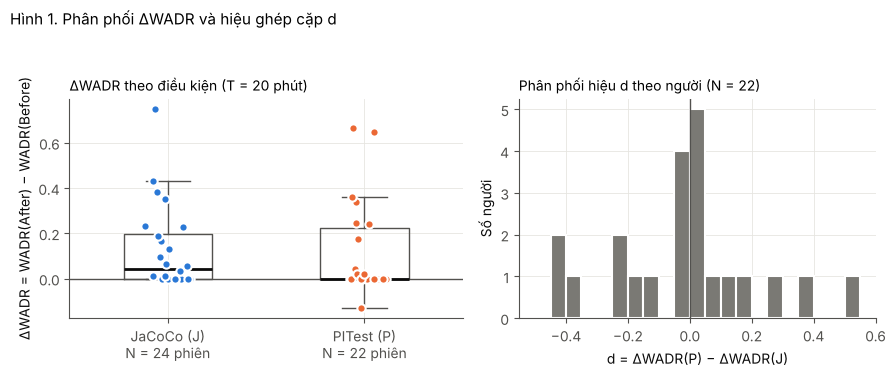

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), gridspec_kw={'width_ratios': [1.1, 1]})
ax = axes[0]
rng = np.random.default_rng(2026)
for i, dk in enumerate('JP'):
    v = ph.loc[ph.dk == dk, 'dWADR'].dropna().to_numpy()
    ax.boxplot(v, positions=[i], widths=0.45, showfliers=False, medianprops={'color': '#0b0b0b', 'lw': 2},
               boxprops={'color': '#52514e'}, whiskerprops={'color': '#52514e'}, capprops={'color': '#52514e'})
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(v)), v, s=36, color=COL[dk], edgecolor='white', linewidth=1.5, zorder=3)
ax.axhline(0, color='#52514e', lw=1)
ax.set_xticks([0, 1], [f'JaCoCo (J)\nN = {ph[(ph.dk == "J")].dWADR.notna().sum()} phiên', f'PITest (P)\nN = {ph[(ph.dk == "P")].dWADR.notna().sum()} phiên'])
ax.set_ylabel('ΔWADR = WADR(After) − WADR(Before)'); ax.set_title('ΔWADR theo điều kiện (T = 20 phút)', loc='left', fontsize=10)
ax = axes[1]
ax.hist(d, bins=np.arange(-0.5, 0.6, 0.05), color='#7a7974', edgecolor='white', linewidth=1.5)
ax.axvline(0, color='#52514e', lw=1)
ax.set_xlabel('d = ΔWADR(P) − ΔWADR(J)'); ax.set_ylabel('Số người')
ax.set_title(f'Phân phối hiệu d theo người (N = {len(d)})', loc='left', fontsize=10)
fig.suptitle('Hình 1. Phân phối ΔWADR và hiệu ghép cặp d', x=0.01, ha='left', fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.93)); fig.savefig(FIG / 'fig1_distribution.png', dpi=300); plt.show()

## 4. Kiểm giả định của Wilcoxon signed-rank ghép cặp

In [7]:
print(f'Độ lệch (skewness) của d: {stats.skew(d):.3f}; trung bình {d.mean():.4f} so với trung vị {np.median(d):.4f}')
print('Hiệu d của các người là độc lập theo người, nhưng các người dùng chung bài (mỗi bài 4 phiên): hiệu ứng bài được xét ở phân tích bổ sung (mô hình hỗn hợp, §6).')
print('Có', int((d == 0).sum()), 'hiệu bằng 0 và', len(d[d != 0]) - len(np.unique(np.abs(d[d != 0]))), 'hạng trùng -> theo §6: Pratt, p xấp xỉ chuẩn có hiệu chỉnh hạng trùng.')
print('Histogram ở Hình 1 không cho thấy lệch mạnh về một phía; giữ kiểm định đã đăng ký, không đổi theo dữ liệu.')

Độ lệch (skewness) của d: 0.258; trung bình -0.0202 so với trung vị -0.0054
Hiệu d của các người là độc lập theo người, nhưng các người dùng chung bài (mỗi bài 4 phiên): hiệu ứng bài được xét ở phân tích bổ sung (mô hình hỗn hợp, §6).
Có 4 hiệu bằng 0 và 0 hạng trùng -> theo §6: Pratt, p xấp xỉ chuẩn có hiệu chỉnh hạng trùng.
Histogram ở Hình 1 không cho thấy lệch mạnh về một phía; giữ kiểm định đã đăng ký, không đổi theo dữ liệu.


## 5. Kiểm định chính và 6. effect size

In [8]:
def hl_ci(d, conf=0.95):
    # khoảng tin cậy Hodges–Lehmann bằng nghịch đảo Wilcoxon (Hollander et al. 2013), xấp xỉ chuẩn, trên mọi d kể cả d = 0
    d = np.asarray(d, float); n = len(d)
    wa = np.sort([(d[i] + d[j]) / 2 for i in range(n) for j in range(i, n)])
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    k = int(math.floor(n * (n + 1) / 4 - z * math.sqrt(n * (n + 1) * (2 * n + 1) / 24)))
    return wa[k], wa[len(wa) - 1 - k]
def rank_biserial(d):
    # rank-biserial ghép cặp (Kerby 2014): (tổng hạng dương − tổng hạng âm) / tổng hạng, trên các d khác 0; > 0 nghiêng về PITest
    d = np.asarray(d, float); d = d[d != 0]
    r = stats.rankdata(np.abs(d)); return (r[d > 0].sum() - r[d < 0].sum()) / r.sum()
def phan_tich(d, nhan, delta=DELTA):
    d = np.asarray(d, float)
    stat, p = cm.wilcoxon_pratt(d); hl = cm.hodges_lehmann(d); lo, hi = hl_ci(d)
    return {'phan_tich': nhan, 'N_hop_le': len(d), 'so_d_bang_0': int((d == 0).sum()), 'trung_vi_d': float(np.median(d)),
            'Q1_d': float(np.quantile(d, .25)), 'Q3_d': float(np.quantile(d, .75)), 'kiem_dinh': 'Wilcoxon signed-rank ghép cặp, hai phía, Pratt',
            'thong_ke': stat, 'p': p, 'HL_theta': hl, 'CI95_thap': lo, 'CI95_cao': hi, 'rank_biserial_r': rank_biserial(d),
            'delta': delta, 'ket_luan': cm.decide(p, hl, ALPHA, delta), 'H0': 'bác bỏ' if p < ALPHA else 'không bác bỏ'}
chinh = phan_tich(d, 'Chính: T = 20, After không biên dịch không tính')
pd.Series(chinh)

phan_tich          Chính: T = 20, After không biên dịch không tính
N_hop_le                                                        22
so_d_bang_0                                                      4
trung_vi_d                                               -0.005435
Q1_d                                                     -0.174217
Q3_d                                                      0.061279
kiem_dinh           Wilcoxon signed-rank ghép cặp, hai phía, Pratt
thong_ke                                                     100.0
p                                                         0.483436
HL_theta                                                 -0.011719
CI95_thap                                                -0.117751
CI95_cao                                                  0.073885
rank_biserial_r                                          -0.157895
delta                                                          0.1
ket_luan                                       chưa thấy khác 

## 7. Phân tích bổ sung và độ nhạy (đã nêu trong proposal §6)

In [9]:
out = [chinh]
def d_of(T_, loi='bo', col=None, before_col=None, drop=None):
    s = cm.load_sessions(PHIEN, LICH, T_, loi)
    if col:   # thước đo khác (phụ, giữ bất đồng AC)
        m = ph.set_index('session_id')
        for x in s:
            b, a = m.loc[x['session_id'], before_col], m.loc[x['session_id'], col]
            x['WADR_before'], x['WADR_after'] = b, (None if pd.isna(a) else a)
            x['dWADR'] = None if x['WADR_after'] is None else x['WADR_after'] - b
    p = pd.DataFrame(cm.paired(s))
    if drop is not None: p = p[~p.sv_id.isin(drop)]
    return p.loc[p.trong_phan_tich, 'd'].astype(float).to_numpy()
for T_ in ['after_T20', 'after_T15', 'after_T30']:
    for loi in ['bo', 'bang_0']:
        if (T_, loi) != ('after_T20', 'bo'):
            out.append(phan_tich(d_of(T_, loi), f'Độ nhạy: T = {T_[-2:]}, After không biên dịch ' + ('= 0' if loi == 'bang_0' else 'không tính')))
for dl in [0.05, 0.15]:
    out.append(phan_tich(d, f'Độ nhạy ngưỡng δ = {dl}', delta=dl))
out.append(phan_tich(d_of(T, col='giu_after', before_col='giu_before'), 'Độ nhạy: giữ mọi test bất đồng AC'))
out.append(phan_tich(d_of(T, col='phu_after', before_col='phu_before'), 'Thước đo phụ (§5.10): tính cả WA làm test hợp lệ báo lỗi do ngoại lệ'))
# độ nhạy về báo cáo (§6 (i)): bỏ người có phiên ở bài + điều kiện mà báo cáo của bộ Sample có số mục không phủ/diệt được bằng tập tham chiếu nhiều hơn số mục phủ/diệt được
co_muc_kho = {('J', p) for p in ['p03196', 'p00144', 'p03253', 'p01125']} | {('P', p) for p in ['p03378', 'p03253', 'p00144', 'p03274']}
bo_sv = sorted(ph[[ (r.dk, r.pid) in co_muc_kho for r in ph.itertuples()]].sv_id.unique())
out.append(phan_tich(d_of(T, drop=bo_sv), f'Độ nhạy báo cáo: bỏ {len(bo_sv)} người có phiên ở bài + điều kiện có nhiều mục không phủ/diệt được'))
summary_tests = pd.DataFrame(out)
summary_tests[['phan_tich', 'N_hop_le', 'so_d_bang_0', 'HL_theta', 'CI95_thap', 'CI95_cao', 'p', 'rank_biserial_r', 'ket_luan']].round(4)

,phan_tich,N_hop_le,so_d_bang_0,HL_theta,CI95_thap,CI95_cao,p,rank_biserial_r,ket_luan
0,"Chính: T = 20, After không biên dịch không tính",22,4,-0.0117,-0.1178,0.0739,0.4834,-0.1579,chưa thấy khác biệt
1,"Độ nhạy: T = 20, After không biên dịch = 0",24,5,-0.0163,-0.1261,0.0627,0.3504,-0.2105,chưa thấy khác biệt
2,"Độ nhạy: T = 15, After không biên dịch không tính",23,4,0.0000,-0.0898,0.1408,0.9270,0.0316,chưa thấy khác biệt
3,"Độ nhạy: T = 15, After không biên dịch = 0",24,4,-0.0056,-0.0961,0.1256,0.7744,-0.0190,chưa thấy khác biệt
4,"Độ nhạy: T = 30, After không biên dịch không tính",22,4,-0.0117,-0.1287,0.0739,0.5040,-0.1462,chưa thấy khác biệt
5,"Độ nhạy: T = 30, After không biên dịch = 0",24,5,-0.0163,-0.1287,0.0536,0.3654,-0.2000,chưa thấy khác biệt
6,Độ nhạy ngưỡng δ = 0.05,22,4,-0.0117,-0.1178,0.0739,0.4834,-0.1579,chưa thấy khác biệt
7,Độ nhạy ngưỡng δ = 0.15,22,4,-0.0117,-0.1178,0.0739,0.4834,-0.1579,chưa thấy khác biệt
8,Độ nhạy: giữ mọi test bất đồng AC,22,4,-0.0117,-0.1178,0.0738,0.4834,-0.1579,chưa thấy khác biệt
9,Thước đo phụ (§5.10): tính cả WA làm test hợp ...,22,3,-0.0185,-0.1304,0.0736,0.4069,-0.1895,chưa thấy khác biệt


In [10]:
# Mỗi lần chạy công cụ: có báo cáo / công cụ báo lỗi (PITest dừng khi bộ test có test fail trên chương trình) / bộ test không biên dịch
def ket_qua_chay(sid, k):
    d = PHIEN / sid / f'tool_r{k}'
    if (d / 'summary.json').exists(): return 'có báo cáo'
    if (d / 'pit_log.txt').exists():
        t = (d / 'pit_log.txt').read_text(encoding='utf-8', errors='replace')
        return 'công cụ báo lỗi: có test fail trên chương trình' if 'did not pass without mutation' in t else 'công cụ báo lỗi khác'
    return 'không chạy được: bộ test không biên dịch'
runs = pd.DataFrame([{'session_id': r.session_id, 'dk': r.dk, 'lan': k, 'ket_qua': ket_qua_chay(r.session_id, k)} for r in ph.itertuples() for k in range(1, 5)])
print('Kết quả 4 lần chạy công cụ của mỗi phiên (lần 1 = trên Before.java), theo điều kiện:')
display(runs.pivot_table(index=['dk', 'ket_qua'], columns='lan', values='session_id', aggfunc='count', fill_value=0))
print('Báo cáo rỗng ở lần chạy đầu tiên:', {dk: f"{int(ph.loc[ph.dk == dk, 'bao_cao_rong'].fillna(False).sum())}/{int((ph.dk == dk).sum())}" for dk in 'JP'})
ph['P_co_bao_cao'] = ph.session_id.map(runs[runs.ket_qua == 'có báo cáo'].groupby('session_id').size()).fillna(0).astype(int)
print('Hiệu ứng trần (After T20):')
for dk in 'JP':
    a = ph.loc[ph.dk == dk, 'WADR_after'].dropna()
    print(f'  {dk}: ≥ 0,95 ở {int((a >= .95).sum())}/{len(a)}; = 1,00 ở {int((a == 1).sum())}/{len(a)}')
print('Test bất đồng AC ở After T20 theo điều kiện:', ph.groupby('dk').bat_dong_AC_after.sum().to_dict(),
      '(chưa duyệt tay; danh sách để duyệt: results/thucnghiem_24/duyet_bat_dong_AC.csv)')

Kết quả 4 lần chạy công cụ của mỗi phiên (lần 1 = trên Before.java), theo điều kiện:


lan                                                  1   2   3   4
dk ket_qua                                                        
J  có báo cáo                                       24  24  24  24
P  có báo cáo                                       12   5   7   6
   công cụ báo lỗi: có test fail trên chương trình  10  16  16  16
   không chạy được: bộ test không biên dịch          2   3   1   2

Báo cáo rỗng ở lần chạy đầu tiên: {'J': '2/24', 'P': '0/24'}
Hiệu ứng trần (After T20):
  J: ≥ 0,95 ở 0/24; = 1,00 ở 0/24
  P: ≥ 0,95 ở 1/22; = 1,00 ở 0/22
Test bất đồng AC ở After T20 theo điều kiện: {'J': 3, 'P': 0} (chưa duyệt tay; danh sách để duyệt: results/thucnghiem_24/duyet_bat_dong_AC.csv)


In [11]:
# Mô hình tuyến tính hỗn hợp (§6): ΔWADR ~ điều kiện + thứ tự phiên + bài, hiệu ứng ngẫu nhiên theo người
m = ph.dropna(subset=['dWADR']).copy()
def mixed(formula, nhan):
    for meth in ['lbfgs', 'bfgs', 'powell']:   # lbfgs báo ma trận suy biến ở dữ liệu này; thử thuật toán khác, ghi lại thuật toán hội tụ
        try:
            fit = smf.mixedlm(formula, m, groups=m['sv_id']).fit(reml=True, method=meth)
            if fit.converged: break
        except Exception:
            continue
    ci = fit.conf_int().loc['C(dk)[T.P]']
    return {'phan_tich': f'{nhan} (REML, {meth})', 'he_so_P': fit.params['C(dk)[T.P]'], 'CI95_thap': ci[0], 'CI95_cao': ci[1], 'p': fit.pvalues['C(dk)[T.P]'], 'N_phien': int(fit.nobs)}
mm = [mixed('dWADR ~ C(dk) + C(phien) + C(pid)', 'Mô hình hỗn hợp: điều kiện + thứ tự + bài'),
      mixed('dWADR ~ C(dk) + C(phien) + C(pid) + dau_vao_after', 'Mô hình hỗn hợp + số đầu vào độc lập (After)'),
      mixed('dWADR ~ C(dk) + C(phien) + C(pid) + WADR_before', 'Mô hình hỗn hợp + WADR(Before)')]
# crossover 2x2: hồi quy d theo nhóm thứ tự (+0,5 = JaCoCo trước, −0,5 = PITest trước)
pp = pr[pr.trong_phan_tich].copy()
first = ph[ph.phien == 1].set_index('sv_id').dk
pp['nhom'] = [0.5 if first[s] == 'J' else -0.5 for s in pp.sv_id]
ols = smf.ols('d ~ nhom', pp.assign(d=pp.d.astype(float))).fit()
mm.append({'phan_tich': 'Crossover 2×2: d ~ nhóm thứ tự (hệ số chặn = θ đã tách thứ tự)', 'he_so_P': ols.params['Intercept'],
           'CI95_thap': ols.conf_int().loc['Intercept'][0], 'CI95_cao': ols.conf_int().loc['Intercept'][1], 'p': ols.pvalues['Intercept'], 'N_phien': int(ols.nobs) * 2})
mm.append({'phan_tich': 'Crossover 2×2: hiệu ứng thứ tự (hệ số nhóm / 2)', 'he_so_P': ols.params['nhom'] / 2,
           'CI95_thap': ols.conf_int().loc['nhom'][0] / 2, 'CI95_cao': ols.conf_int().loc['nhom'][1] / 2, 'p': ols.pvalues['nhom'], 'N_phien': int(ols.nobs) * 2})
models = pd.DataFrame(mm)
print('Ghi chú: phương sai hiệu ứng ngẫu nhiên theo người ước lượng gần 0 (cảnh báo biên của statsmodels); hệ số điều kiện vẫn ước lượng được.')
models.round(4)

Ghi chú: phương sai hiệu ứng ngẫu nhiên theo người ước lượng gần 0 (cảnh báo biên của statsmodels); hệ số điều kiện vẫn ước lượng được.


/usr/local/lib/python3.13/site-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/usr/local/lib/python3.13/site-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/tmp/ipykernel_150/2850351913.py:6: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = smf.mixedlm(formula, m, groups=m['sv_id']).fit(reml=True, method=meth)
/usr/local/lib/python3.13/site-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs


,phan_tich,he_so_P,CI95_thap,CI95_cao,p,N_phien
0,Mô hình hỗn hợp: điều kiện + thứ tự + bài (REM...,-0.0100,-0.1008,0.0808,0.8291,46
1,Mô hình hỗn hợp + số đầu vào độc lập (After) (...,-0.0281,-0.0935,0.0373,0.3990,46
2,"Mô hình hỗn hợp + WADR(Before) (REML, bfgs)",-0.0095,-0.1041,0.0851,0.8437,46
3,Crossover 2×2: d ~ nhóm thứ tự (hệ số chặn = θ...,-0.0206,-0.1302,0.0891,0.6996,44
4,Crossover 2×2: hiệu ứng thứ tự (hệ số nhóm / 2),0.0044,-0.1052,0.1141,0.9337,44


In [12]:
# Nhóm con (§6): từng bài (mô tả, không kiểm định) và mức WADR ban đầu dưới / trên trung vị
bai = ph.dropna(subset=['dWADR']).pivot_table(index='pid', columns='dk', values='dWADR', aggfunc=['mean', 'count'])
bai.columns = [f'{a}_{b}' for a, b in bai.columns]
bai['d_bai = TB(P) − TB(J)'] = bai['mean_P'] - bai['mean_J']
print('Theo bài (ΔWADR trung bình mỗi điều kiện, số phiên):'); display(bai.round(4))
nen = ph.groupby('sv_id').WADR_before.mean()
pp['nen'] = pp.sv_id.map(nen)
med = pp.nen.median()
for ten, g in [('WADR ban đầu ≤ trung vị', pp[pp.nen <= med]), ('WADR ban đầu > trung vị', pp[pp.nen > med])]:
    out.append(phan_tich(g.d.astype(float).to_numpy(), f'Nhóm con: {ten} (trung vị {med:.3f})'))
# exploratory (không có trong proposal): chỉ những người mà phiên PITest nhận được ít nhất một báo cáo PITest
co_bc = set(ph[(ph.dk == 'P') & (ph.P_co_bao_cao > 0)].sv_id)
out.append(phan_tich(pp[pp.sv_id.isin(co_bc)].d.astype(float).to_numpy(), 'Exploratory: chỉ người có ít nhất một báo cáo PITest trong phiên P'))
pd.DataFrame(out[-3:])[['phan_tich', 'N_hop_le', 'HL_theta', 'CI95_thap', 'CI95_cao', 'p', 'ket_luan']].round(4)

Theo bài (ΔWADR trung bình mỗi điều kiện, số phiên):


,mean_J,mean_P,count_J,count_P,d_bai = TB(P) − TB(J)
pid,,,,,
p00003,0.2153,0.0000,2,2,-0.2153
p00144,0.0000,0.0000,2,2,0.0000
p01125,0.0000,0.1690,2,2,0.1690
p02263,0.0054,0.0217,2,2,0.0163
p03196,0.3913,-0.1304,2,1,-0.5217
p03253,0.2414,0.2414,2,1,-0.0000
p03274,0.0483,0.0093,2,2,-0.0389
p03351,0.1222,0.2104,2,2,0.0882
p03378,0.1146,0.6562,2,2,0.5417


,phan_tich,N_hop_le,HL_theta,CI95_thap,CI95_cao,p,ket_luan
0,Nhóm con: WADR ban đầu ≤ trung vị (trung vị 0....,11,-0.0163,-0.1785,0.0374,0.2713,chưa thấy khác biệt
1,Nhóm con: WADR ban đầu > trung vị (trung vị 0....,11,-0.0012,-0.2004,0.2619,1.0000,chưa thấy khác biệt
2,Exploratory: chỉ người có ít nhất một báo cáo ...,11,-0.0199,-0.2121,0.1797,0.6231,chưa thấy khác biệt


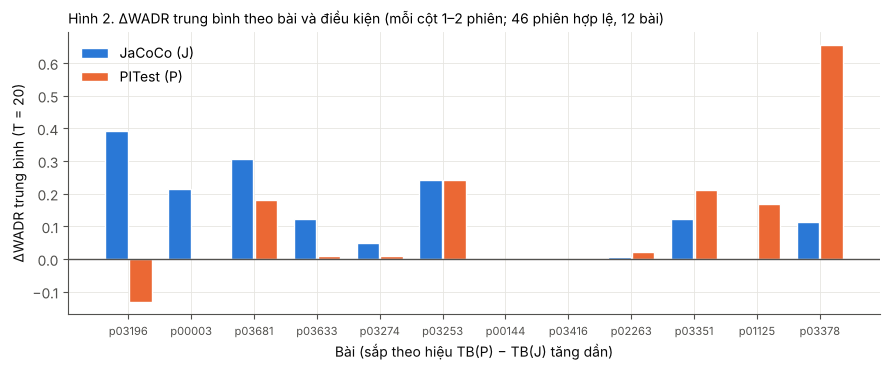

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.8))
order = bai.sort_values('d_bai = TB(P) − TB(J)').index
x = np.arange(len(order))
ax.bar(x - 0.19, bai.loc[order, 'mean_J'], width=0.36, color=COL['J'], label='JaCoCo (J)', edgecolor='white', linewidth=1)
ax.bar(x + 0.19, bai.loc[order, 'mean_P'], width=0.36, color=COL['P'], label='PITest (P)', edgecolor='white', linewidth=1)
ax.axhline(0, color='#52514e', lw=1)
ax.set_xticks(x, order, rotation=0, fontsize=8); ax.set_ylabel('ΔWADR trung bình (T = 20)'); ax.set_xlabel('Bài (sắp theo hiệu TB(P) − TB(J) tăng dần)')
ax.set_title('Hình 2. ΔWADR trung bình theo bài và điều kiện (mỗi cột 1–2 phiên; 46 phiên hợp lệ, 12 bài)', loc='left', fontsize=10)
ax.legend(frameon=False, loc='upper left')
fig.tight_layout(); fig.savefig(FIG / 'fig2_comparison.png', dpi=300); plt.show()

## 7b. Số liệu cho §5 Discussion (mô tả)

Lý do test không hợp lệ ở After (T = 20), phân loại phiên không cải thiện, ΔWADR của phiên PITest có và không có báo cáo, thời gian chạy công cụ.

In [14]:
import collections
ly_do = collections.Counter(); hop_le = collections.defaultdict(lambda: [0, 0]); khong_tang = collections.Counter()
for r in rows:
    a, b = r['summary']['bo_test'][T], r['summary']['bo_test']['before']
    if a.get('bien_dich') != 'ok': continue
    for t in a['test_khong_hop_le']:
        x = t['ly_do']
        k = ('fail trên chương trình (expected sai)' if 'FAIL trên PUT' in x else 'ngoại lệ trên chương trình' if 'ERROR trên PUT' in x
             else 'ngoài ràng buộc' if 'ràng buộc' in x else 'quá giờ' if 'TIMEOUT' in x else 'khác')
        ly_do[(r['dk'], k)] += 1
    hop_le[r['dk']][0] += a['test_hop_le']; hop_le[r['dk']][1] += a['so_test']
    wb = b.get('WA_phat_hien_assertion', 0) if b.get('bien_dich') == 'ok' else 0
    if a['WA_phat_hien_assertion'] == wb:
        ib = b.get('dau_vao_doc_lap', 0) if b.get('bien_dich') == 'ok' else 0
        khong_tang[(r['dk'], 'không thêm đầu vào hợp lệ mới' if a['dau_vao_doc_lap'] <= ib else 'có đầu vào mới nhưng không bắt thêm WA')] += 1
print('Lý do test không hợp lệ (After T20):'); display(pd.Series(ly_do).unstack(0).fillna(0).astype(int))
print('Tỉ lệ test hợp lệ (After T20):', {k: f'{v[0]}/{v[1]} = {v[0] / v[1]:.0%}' for k, v in hop_le.items()})
print('Phiên ΔWADR = 0:', dict(khong_tang))
gp = ph[(ph.dk == 'P') & ph.dWADR.notna()]
print('ΔWADR TB phiên P có ≥ 1 báo cáo PITest:', round(gp[gp.P_co_bao_cao > 0].dWADR.mean(), 3), f'({int((gp.P_co_bao_cao > 0).sum())} phiên);',
      'không có báo cáo:', round(gp[gp.P_co_bao_cao == 0].dWADR.mean(), 3), f'({int((gp.P_co_bao_cao == 0).sum())} phiên)  [exploratory]')
tg = pd.read_csv(ROOT / 'results' / 'thucnghiem_24' / 'phien_thucnghiem_24.csv')
print('Thời gian TB một lần chạy công cụ (giây, trung bình các phiên):', tg.merge(ph[['session_id', 'dk']], on='session_id').groupby('dk').tool_giay_tb.mean().round(1).to_dict())

Lý do test không hợp lệ (After T20):


,J,P
fail trên chương trình (expected sai),72,60
ngoài ràng buộc,21,13
ngoại lệ trên chương trình,34,47
quá giờ,2,0


Tỉ lệ test hợp lệ (After T20): {'J': '91/223 = 41%', 'P': '90/210 = 43%'}
Phiên ΔWADR = 0: {('P', 'không thêm đầu vào hợp lệ mới'): 9, ('J', 'không thêm đầu vào hợp lệ mới'): 8, ('P', 'có đầu vào mới nhưng không bắt thêm WA'): 2, ('J', 'có đầu vào mới nhưng không bắt thêm WA'): 1}
ΔWADR TB phiên P có ≥ 1 báo cáo PITest: 0.173 (11 phiên); không có báo cáo: 0.066 (11 phiên)  [exploratory]
Thời gian TB một lần chạy công cụ (giây, trung bình các phiên): {'J': 6.9, 'P': 7.2}


## Ghi `results/summary.csv`

In [15]:
rows_s = []
for m_, ten in [('WADR_before', 'WADR(Before)'), ('WADR_after', 'WADR(After, T = 20)'), ('dWADR', 'ΔWADR (T = 20)')]:
    for dk in 'JP':
        x = ph.loc[ph.dk == dk, m_].dropna()
        rows_s.append({'metric': ten, 'dieu_kien': dk, 'N_hop_le': len(x), 'trung_vi': x.median(), 'Q1': x.quantile(.25), 'Q3': x.quantile(.75)})
for r in out:
    rows_s.append({'metric': 'd = ΔWADR(P) − ΔWADR(J)', 'dieu_kien': 'P − J', 'phan_tich': r['phan_tich'], 'N_hop_le': r['N_hop_le'],
                   'trung_vi': r['trung_vi_d'], 'Q1': r['Q1_d'], 'Q3': r['Q3_d'], 'kiem_dinh': r['kiem_dinh'], 'thong_ke': r['thong_ke'], 'p': r['p'],
                   'HL_theta': r['HL_theta'], 'CI95_thap': r['CI95_thap'], 'CI95_cao': r['CI95_cao'], 'effect_size': r['rank_biserial_r'],
                   'loai_effect_size': 'rank-biserial r ghép cặp', 'delta': r['delta'], 'ket_luan': r['ket_luan'], 'H0': r['H0'],
                   'nhan': 'exploratory' if r['phan_tich'].startswith(('Nhóm con', 'Exploratory')) else ''})
for r in mm:
    rows_s.append({'metric': 'ΔWADR (T = 20)', 'dieu_kien': 'P so với J', 'phan_tich': r['phan_tich'], 'N_hop_le': r['N_phien'],
                   'kiem_dinh': 'mô hình hỗn hợp / OLS', 'p': r['p'], 'HL_theta': None, 'effect_size': r['he_so_P'],
                   'loai_effect_size': 'hệ số hồi quy (đơn vị ΔWADR)', 'CI95_thap': r['CI95_thap'], 'CI95_cao': r['CI95_cao']})
S = pd.DataFrame(rows_s)
S.to_csv(ROOT / 'results' / 'summary.csv', index=False, encoding='utf-8')
print('Đã ghi results/summary.csv:', len(S), 'dòng')

Đã ghi results/summary.csv: 25 dòng


## 8. Kết luận RQ1

In [16]:
c = chinh
print(f"RQ1 (T = 20, N hợp lệ = {c['N_hop_le']}/{N_tham_gia} người; {c['so_d_bang_0']} người có d = 0): "
      f"θ̂ (Hodges–Lehmann) = {c['HL_theta']:+.4f}, KTC 95% [{c['CI95_thap']:+.4f}; {c['CI95_cao']:+.4f}]; "
      f"Wilcoxon (Pratt) W = {c['thong_ke']:.1f}, p = {c['p']:.4f}; rank-biserial r = {c['rank_biserial_r']:+.3f}.")
print(f"-> {c['H0']} H0 (α = {ALPHA}); |θ̂| {'≥' if abs(c['HL_theta']) >= DELTA else '<'} δ = {DELTA}: {c['ket_luan']}.")
print('Theo §6: N = 24 nên nghiên cứu là thăm dò; không bác bỏ H0 không được diễn giải là hai điều kiện tương đương (không chạy TOST).')

RQ1 (T = 20, N hợp lệ = 22/24 người; 4 người có d = 0): θ̂ (Hodges–Lehmann) = -0.0117, KTC 95% [-0.1178; +0.0739]; Wilcoxon (Pratt) W = 100.0, p = 0.4834; rank-biserial r = -0.158.
-> không bác bỏ H0 (α = 0.05); |θ̂| < δ = 0.1: chưa thấy khác biệt.
Theo §6: N = 24 nên nghiên cứu là thăm dò; không bác bỏ H0 không được diễn giải là hai điều kiện tương đương (không chạy TOST).
